<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Stacked Charts**


Estimated time needed: **45** minutes


In this lab, you will focus on visualizing data specifically using stacked charts. You will use SQL queries to extract the necessary data and apply stacked charts to analyze the composition and comparison within the data.


## Objectives


In this lab, you will perform the following:


- Visualize the composition of data using stacked charts.

- Compare multiple variables across different categories using stacked charts.

- Analyze trends within stacked chart visualizations.


## Setup: Downloading and Loading the Data
**Install the libraries**


In [2]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 164.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 146.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]


In [3]:
!pip install matplotlib
!pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 164.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 89.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 160.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



### Step 1: Download the dataset


In [4]:
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  11.6MB/s    in 16s     

2026-10-16 20:08:25 (9.62 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


### Step 2: Import necessary libraries and load the dataset


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mtick

### Load the data


In [6]:
df = pd.read_csv("survey-data.csv")

### Display the first few rows of the data to understand its structure


In [7]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Stacked Chart for Composition of Job Satisfaction Across Age Groups


##### 1. Stacked Chart of Median `JobSatPoints_6` and `JobSatPoints_7` for Different Age Groups


Visualize the composition of job satisfaction scores (`JobSatPoints_6` and `JobSatPoints_7`) across various age groups. This will help in understanding the breakdown of satisfaction levels across different demographics.



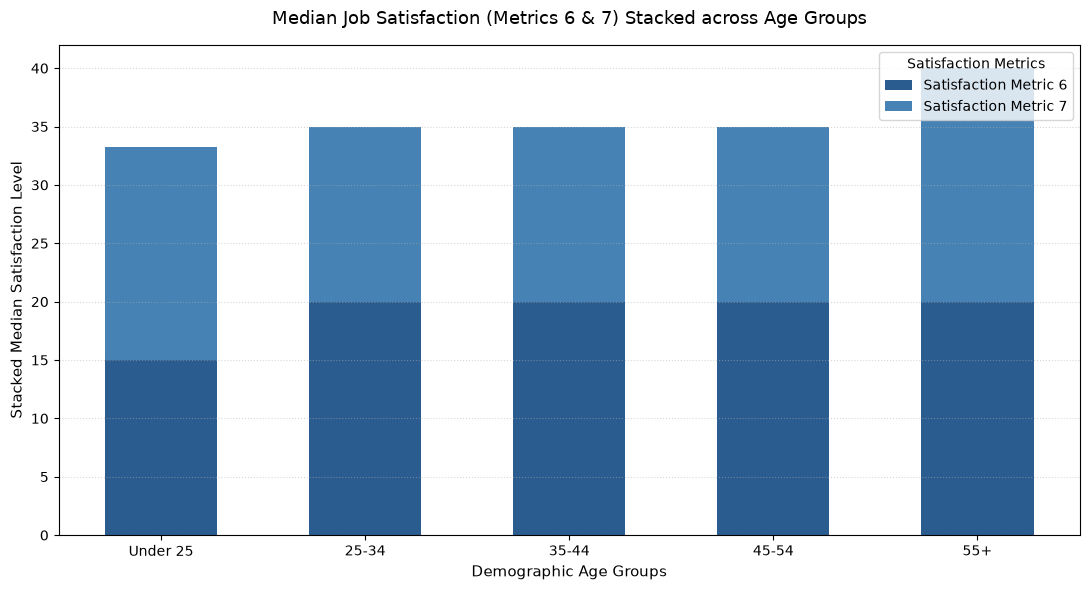

In [8]:
# 1. Enforce numeric typing across target fields
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')
df['JobSatPoints_7'] = pd.to_numeric(df['JobSatPoints_7'], errors='coerce')

# 2. Bin ages into standard, clean demographic brackets
age_bins = [0, 24, 34, 44, 54, np.inf]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels)

# 3. Filter missing fields and group by AgeGroup to compute the MEDIAN
df_clean = df.dropna(subset=['AgeGroup', 'JobSatPoints_6', 'JobSatPoints_7'])
grouped_medians = df_clean.groupby('AgeGroup', observed=True)[['JobSatPoints_6', 'JobSatPoints_7']].median()

# Initialize layout canvas scale properties
plt.figure(figsize=(11, 6))

# Plot the base bar layer (JobSatPoints_6)
plt.bar(
    grouped_medians.index, 
    grouped_medians['JobSatPoints_6'], 
    label='Satisfaction Metric 6', 
    color='#2b5c8f', 
    width=0.55
)

# Plot the stacked bar layer (JobSatPoints_7), anchored to the top of the base layer
plt.bar(
    grouped_medians.index, 
    grouped_medians['JobSatPoints_7'], 
    bottom=grouped_medians['JobSatPoints_6'], # Core stacking mechanic
    label='Satisfaction Metric 7', 
    color='#4682b4', 
    width=0.55
)

# Visual layout adjustments and text styling
plt.title('Median Job Satisfaction (Metrics 6 & 7) Stacked across Age Groups', fontsize=13, pad=15)
plt.xlabel('Demographic Age Groups', fontsize=11)
plt.ylabel('Stacked Median Satisfaction Level', fontsize=11)

# Position the chart legend cleanly
plt.legend(loc='upper right', title='Satisfaction Metrics')

plt.grid(True, axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


##### Stacked Chart of `JobSatPoints_6` and `JobSatPoints_7` for Employment Status


Create a stacked chart to compare job satisfaction (`JobSatPoints_6` and `JobSatPoints_7`) across different employment statuses. This will show how satisfaction varies by employment type.


/tmp/ipykernel_280/1845885371.py:48: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

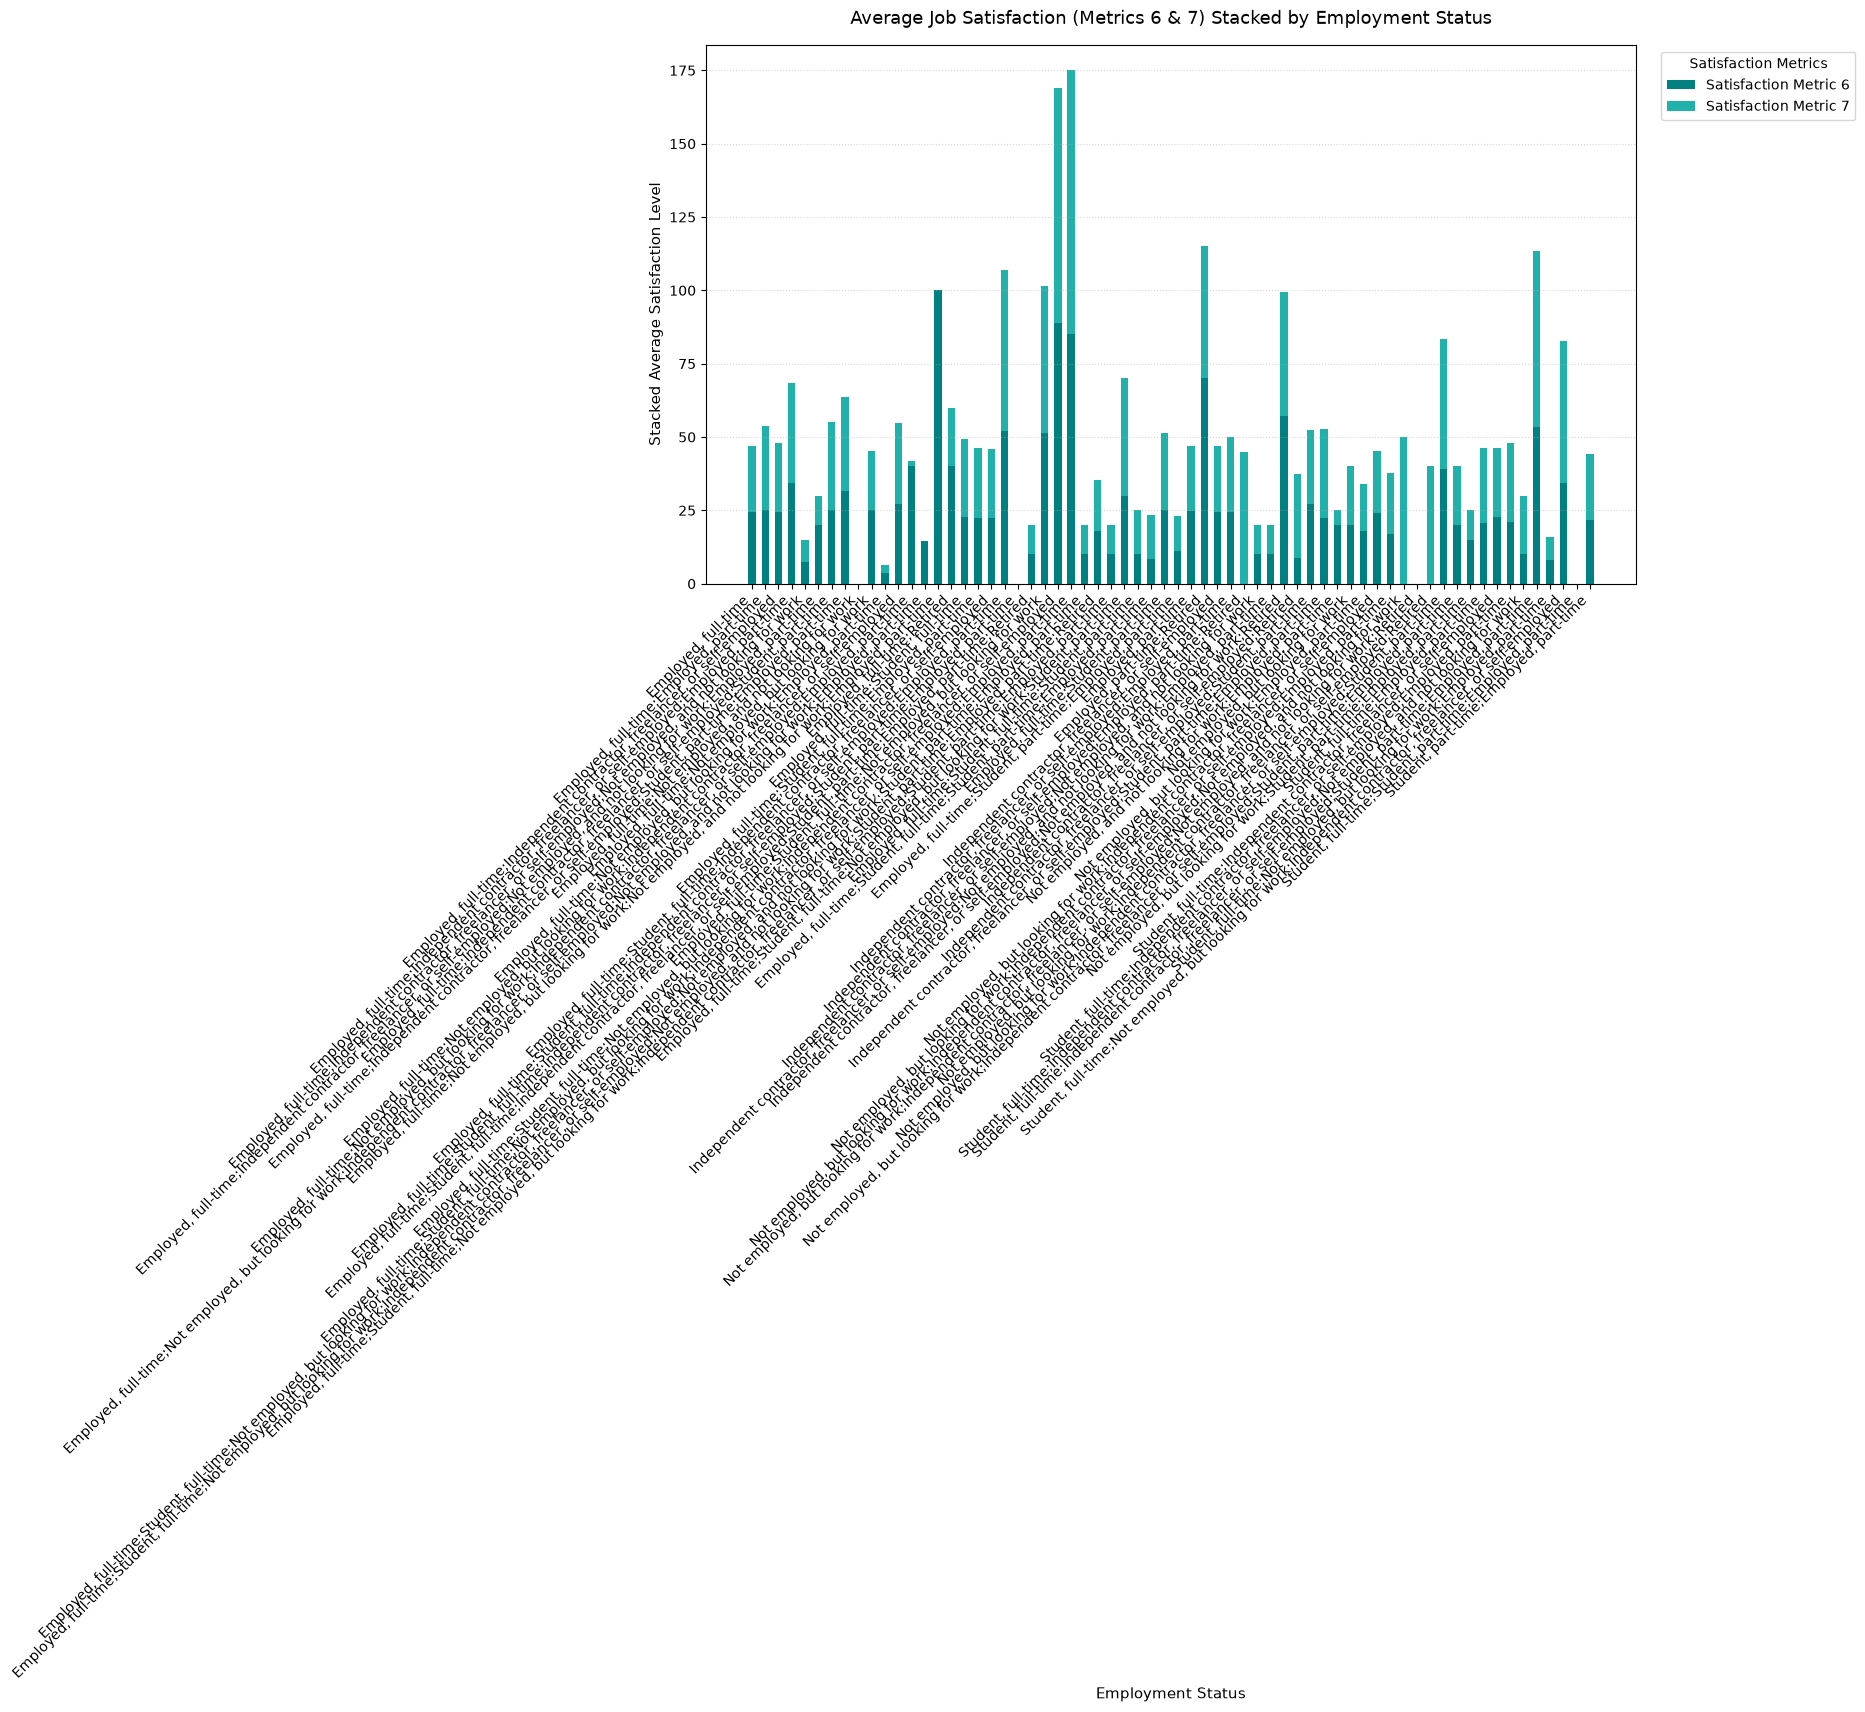

In [9]:
# Enforce uniform numeric types for target satisfaction fields
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')
df['JobSatPoints_7'] = pd.to_numeric(df['JobSatPoints_7'], errors='coerce')

# Drop rows with missing fields in our target dimensional intersections
df_clean = df.dropna(subset=['Employment', 'JobSatPoints_6', 'JobSatPoints_7'])

# Group by Employment type to calculate the average satisfaction levels
grouped_satisfaction = df_clean.groupby('Employment').agg(
    Avg_Sat6=('JobSatPoints_6', 'mean'),
    Avg_Sat7=('JobSatPoints_7', 'mean')
)

# Initialize layout canvas scale properties
plt.figure(figsize=(12, 7))

# Plot the base bar layer (JobSatPoints_6)
plt.bar(
    grouped_satisfaction.index, 
    grouped_satisfaction['Avg_Sat6'], 
    label='Satisfaction Metric 6', 
    color='#008080', 
    width=0.55
)

# Plot the stacked bar layer (JobSatPoints_7), anchored to the top of the base layer
plt.bar(
    grouped_satisfaction.index, 
    grouped_satisfaction['Avg_Sat7'], 
    bottom=grouped_satisfaction['Avg_Sat6'], # Core stacking mechanic
    label='Satisfaction Metric 7', 
    color='#20b2aa', 
    width=0.55
)

# Visual layout adjustments and text styling
plt.title('Average Job Satisfaction (Metrics 6 & 7) Stacked by Employment Status', fontsize=13, pad=15)
plt.xlabel('Employment Status', fontsize=11)
plt.ylabel('Stacked Average Satisfaction Level', fontsize=11)

# Rotate X-axis labels to ensure long category strings don't overlap
plt.xticks(rotation=45, ha='right')

# Position the chart legend cleanly outside of the main chart bounding box
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Satisfaction Metrics')

plt.grid(True, axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 2: Stacked Chart for Compensation and Job Satisfaction by Age Group


##### This stacked chart visualizes the composition of compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) specifically for respondents aged 30-35.


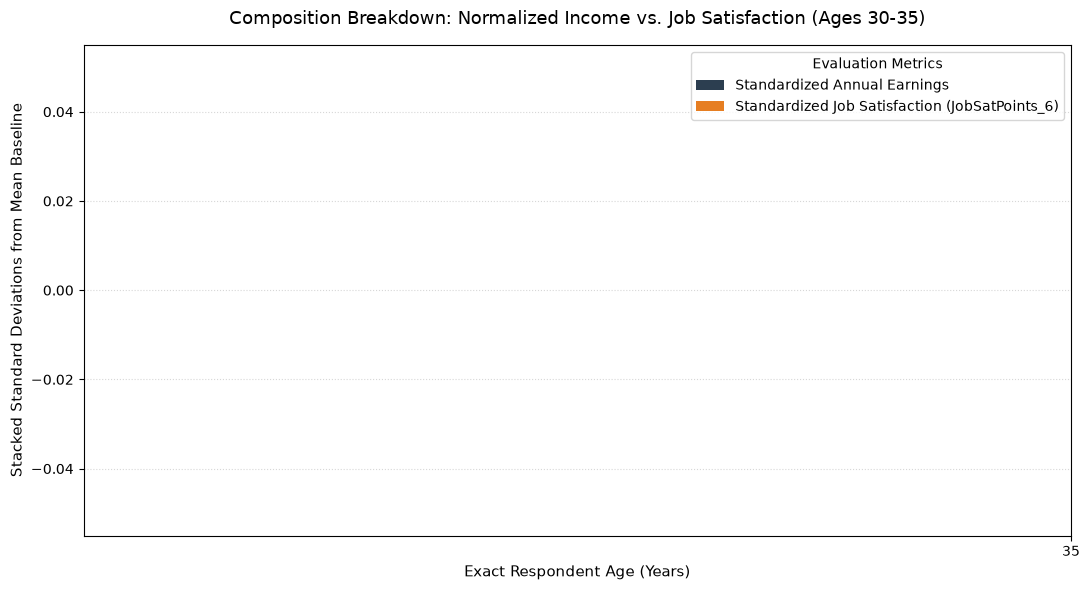

In [10]:
# 1. Enforce numeric formats across continuous and discrete fields
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# 2. Filter strictly for the requested 30-35 age bracket cohort
df_subset = df[(df['Age_Numeric'] >= 30) & (df['Age_Numeric'] <= 35)].copy()
df_clean = df_subset.dropna(subset=['Age_Numeric', 'ConvertedCompYearly', 'JobSatPoints_6'])

# 3. Aggregate metrics to find the mean baseline for each specific age step
age_profile = df_clean.groupby('Age_Numeric').agg(
    Mean_Comp=('ConvertedCompYearly', 'mean'),
    Mean_Sat=('JobSatPoints_6', 'mean')
)

# 4. Standardize via Z-Score normalization to match bar heights perfectly on a shared plane
age_profile['Normalized_Comp'] = (age_profile['Mean_Comp'] - age_profile['Mean_Comp'].mean()) / age_profile['Mean_Comp'].std()
age_profile['Normalized_Sat'] = (age_profile['Mean_Sat'] - age_profile['Mean_Sat'].mean()) / age_profile['Mean_Sat'].std()

# Initialize layout canvas scale properties
plt.figure(figsize=(11, 6))

# Plot the normalized compensation baseline layer
plt.bar(
    age_profile.index.astype(int), 
    age_profile['Normalized_Comp'], 
    label='Standardized Annual Earnings', 
    color='#2c3e50', 
    width=0.45
)

# Stack the normalized job satisfaction metrics on top of the financial baseline
plt.bar(
    age_profile.index.astype(int), 
    age_profile['Normalized_Sat'], 
    bottom=age_profile['Normalized_Comp'], # Core stacking anchor mechanic
    label='Standardized Job Satisfaction (JobSatPoints_6)', 
    color='#e67e22', 
    width=0.45
)

# Layout adjustments and text styling descriptions
plt.title('Composition Breakdown: Normalized Income vs. Job Satisfaction (Ages 30-35)', fontsize=13, pad=15)
plt.xlabel('Exact Respondent Age (Years)', fontsize=11)
plt.ylabel('Stacked Standard Deviations from Mean Baseline', fontsize=11)

plt.xticks(age_profile.index.astype(int))
plt.grid(True, axis='y', linestyle=':', alpha=0.5)

# Clear structural legend mapping
plt.legend(loc='upper right', title='Evaluation Metrics')
plt.tight_layout()
plt.show()


##### Stacked Chart of Median Compensation and Job Satisfaction Across Age Group


Compare the median compensation and job satisfaction metrics across different age groups. This helps visualize how compensation and satisfaction levels differ by age.


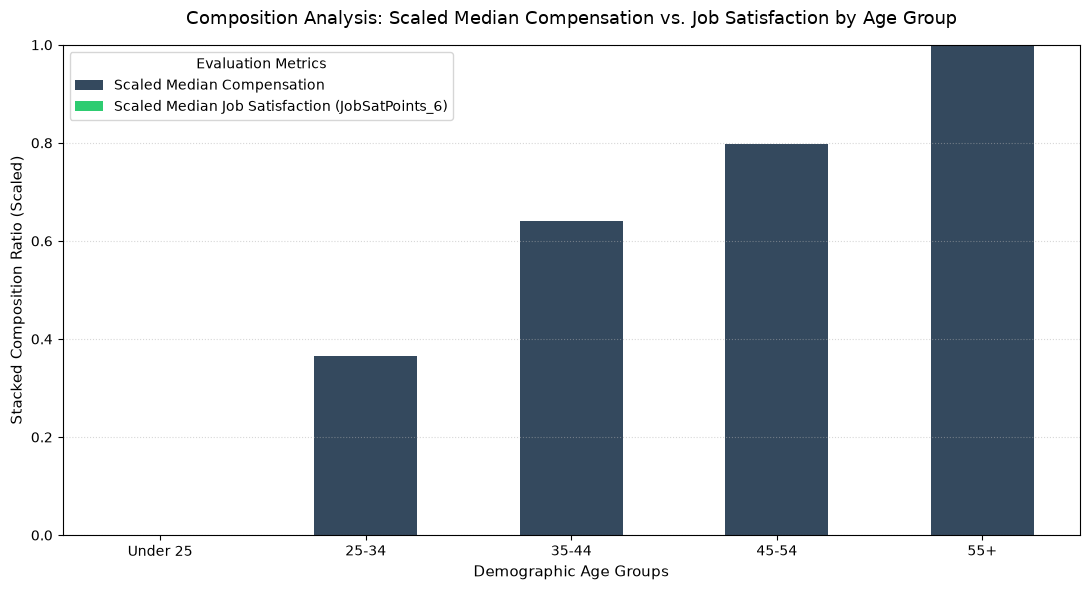

In [11]:
# Enforce clean numeric types for tracking variables
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Bin individual ages into clear, structured Age Groups
age_bins = [0, 24, 34, 44, 54, np.inf]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels)

# Filter missing fields and group by AgeGroup to compute the MEDIAN
df_clean = df.dropna(subset=['AgeGroup', 'ConvertedCompYearly', 'JobSatPoints_6'])
grouped_medians = df_clean.groupby('AgeGroup', observed=True)[['ConvertedCompYearly', 'JobSatPoints_6']].median()

# Scale both columns between 0 and 1 so they display proportionally together
grouped_medians['Scaled_Comp'] = (grouped_medians['ConvertedCompYearly'] - grouped_medians['ConvertedCompYearly'].min()) / (grouped_medians['ConvertedCompYearly'].max() - grouped_medians['ConvertedCompYearly'].min())
grouped_medians['Scaled_Sat'] = (grouped_medians['JobSatPoints_6'] - grouped_medians['JobSatPoints_6'].min()) / (grouped_medians['JobSatPoints_6'].max() - grouped_medians['JobSatPoints_6'].min())

# Initialize layout canvas scale properties
plt.figure(figsize=(11, 6))

# Plot the scaled compensation baseline layer
plt.bar(
    grouped_medians.index, 
    grouped_medians['Scaled_Comp'], 
    label='Scaled Median Compensation', 
    color='#34495e', 
    width=0.5
)

# Stack the scaled job satisfaction metric on top of the financial base layer
plt.bar(
    grouped_medians.index, 
    grouped_medians['Scaled_Sat'], 
    bottom=grouped_medians['Scaled_Comp'], # Core stacking mechanic
    label='Scaled Median Job Satisfaction (JobSatPoints_6)', 
    color='#2ecc71', 
    width=0.5
)

# Visual layout adjustments and text styling
plt.title('Composition Analysis: Scaled Median Compensation vs. Job Satisfaction by Age Group', fontsize=13, pad=15)
plt.xlabel('Demographic Age Groups', fontsize=11)
plt.ylabel('Stacked Composition Ratio (Scaled)', fontsize=11)

# Position the chart legend cleanly
plt.legend(loc='upper left', title='Evaluation Metrics')

plt.grid(True, axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 3: Comparing Data Using Stacked Charts


##### 1. Stacked Chart of Preferred Databases by Age Group




Visualize the top databases that respondents from different age groups wish to learn. Create a stacked chart to show the proportion of each database in each age group.


<Figure size 1200x700 with 0 Axes>

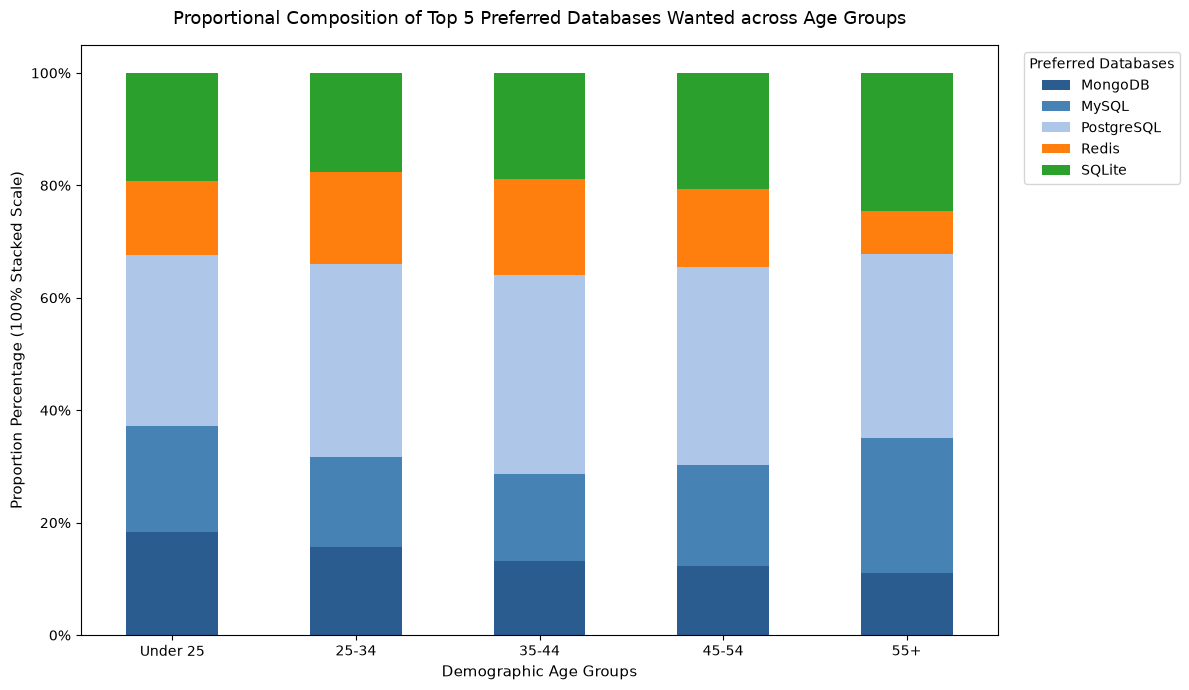

In [13]:
# 1. Clean Age and create categorical Age Groups
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
age_bins = [0, 24, 34, 44, 54, np.inf]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels)

# 2. Isolate relevant columns and drop empty entries
df_db = df.dropna(subset=['DatabaseWantToWorkWith', 'AgeGroup']).copy()

# 3. Split semicolon strings into lists and explode rows
df_db['DatabaseWantToWorkWith'] = df_db['DatabaseWantToWorkWith'].str.split(';')

# FIX: Add .reset_index(drop=True) at the end of explode
df_exploded = df_db.explode('DatabaseWantToWorkWith').reset_index(drop=True)

# 4. Identify the Top 5 overall most desired databases
top_5_dbs = df_exploded['DatabaseWantToWorkWith'].value_counts().nlargest(5).index
df_filtered = df_exploded[df_exploded['DatabaseWantToWorkWith'].isin(top_5_dbs)].copy()


# 5. Cross-tabulate (pivot) to map Age Groups against Database frequencies
# Removing unused categories dynamically keeps the crosstab crisp
df_filtered['AgeGroup'] = df_filtered['AgeGroup'].cat.remove_unused_categories()
ct = pd.crosstab(df_filtered['AgeGroup'], df_filtered['DatabaseWantToWorkWith'])

# 6. Normalize rows to sum up to 1 (100%) to calculate exact proportions
ct_proportions = ct.div(ct.sum(axis=1), axis=0)

# 7. Initialize Canvas and Plot Stacked Structure
plt.figure(figsize=(12, 7))
ax = ct_proportions.plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 7), 
    color=['#2b5c8f', '#4682b4', '#aec7e8', '#ff7f0e', '#2ca02c']
)

# Visual layout adjustments and text formatting
plt.title('Proportional Composition of Top 5 Preferred Databases Wanted across Age Groups', fontsize=13, pad=15)
plt.xlabel('Demographic Age Groups', fontsize=11)
plt.ylabel('Proportion Percentage (100% Stacked Scale)', fontsize=11)

# Format the Y-axis to show percentages cleanly instead of 0.0-1.0 floats
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Rotate labels completely horizontal for scannability
plt.xticks(rotation=0)

# Move the legend block out of the plot box so it doesn't mask data blocks
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Preferred Databases')

plt.tight_layout()
plt.show()



##### 2. Stacked Chart of Employment Type by Job Satisfaction


Analyze the distribution of employment types within each job satisfaction level using a stacked chart. This will provide insights into how employment types are distributed across various satisfaction ratings.


/tmp/ipykernel_280/988809797.py:38: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

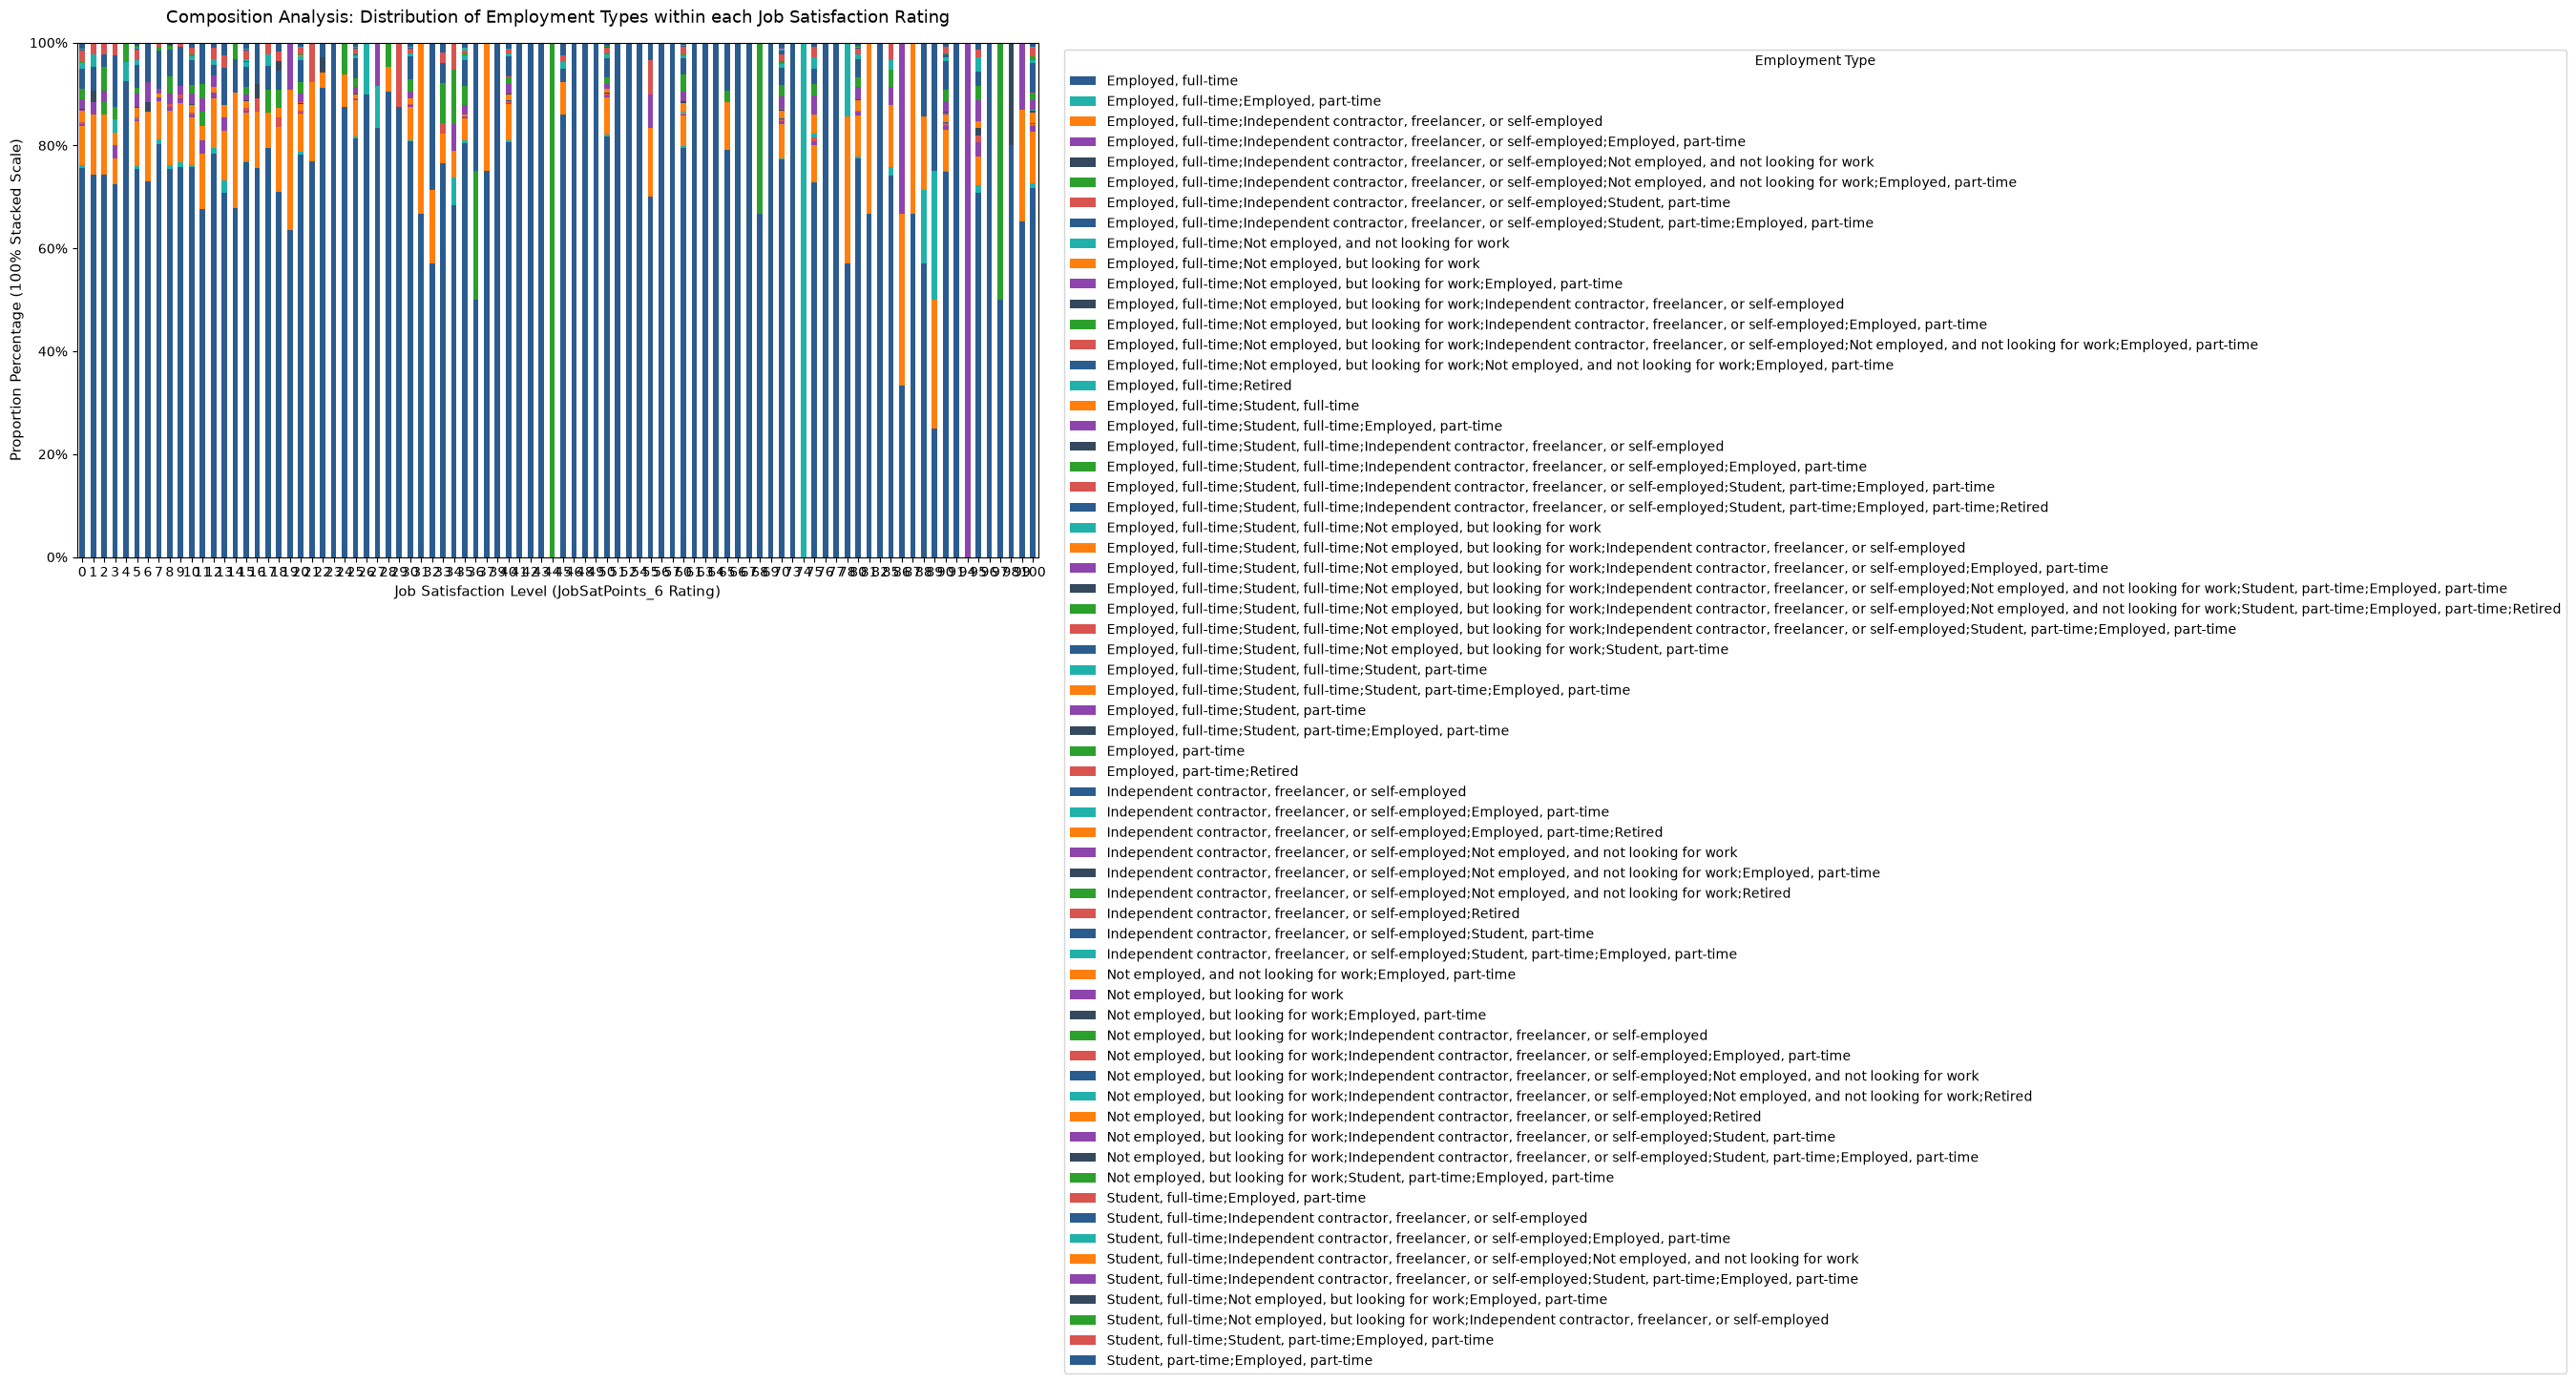

In [14]:
# Enforce clean numeric data structures for the job satisfaction score
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop rows missing critical metrics across our evaluation columns
df_clean = df.dropna(subset=['JobSatPoints_6', 'Employment']).copy()

# Ensure the job satisfaction scores are treated as clean discrete integer strings for the axis tracks
df_clean['JobSatPoints_6'] = df_clean['JobSatPoints_6'].astype(int)

# Cross-tabulate to map satisfaction scores (index/rows) against employment categories (columns)
ct = pd.crosstab(df_clean['JobSatPoints_6'], df_clean['Employment'])

# Normalize the rows to sum up to 1 (100%) to calculate exact inner proportions
ct_proportions = ct.div(ct.sum(axis=1), axis=0)

# Create the stacked proportional chart
ax = ct_proportions.plot(
    kind='bar', 
    stacked=True, 
    figsize=(13, 7), 
    color=['#2b5c8f', '#20b2aa', '#ff7f0e', '#8e44ad', '#34495e', '#2ca02c', '#d9534f']
)

# Visual layout adjustments and text formatting descriptions
plt.title('Composition Analysis: Distribution of Employment Types within each Job Satisfaction Rating', fontsize=13, pad=15)
plt.xlabel('Job Satisfaction Level (JobSatPoints_6 Rating)', fontsize=11)
plt.ylabel('Proportion Percentage (100% Stacked Scale)', fontsize=11)

# Format the Y-axis to show percentages cleanly instead of decimal floats
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Rotate labels slightly for clean layout design reading
plt.xticks(rotation=0)

# Position the chart legend outside the boundaries so it doesn't overlap the segments
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Employment Type')

plt.tight_layout()
plt.show()


### Task 4: Exploring Technology Preferences Using Stacked Charts


##### 1. Stacked Chart for Preferred Programming Languages by Age Group


Analyze how programming language preferences (`LanguageAdmired`) vary across age groups.


<Figure size 1200x700 with 0 Axes>

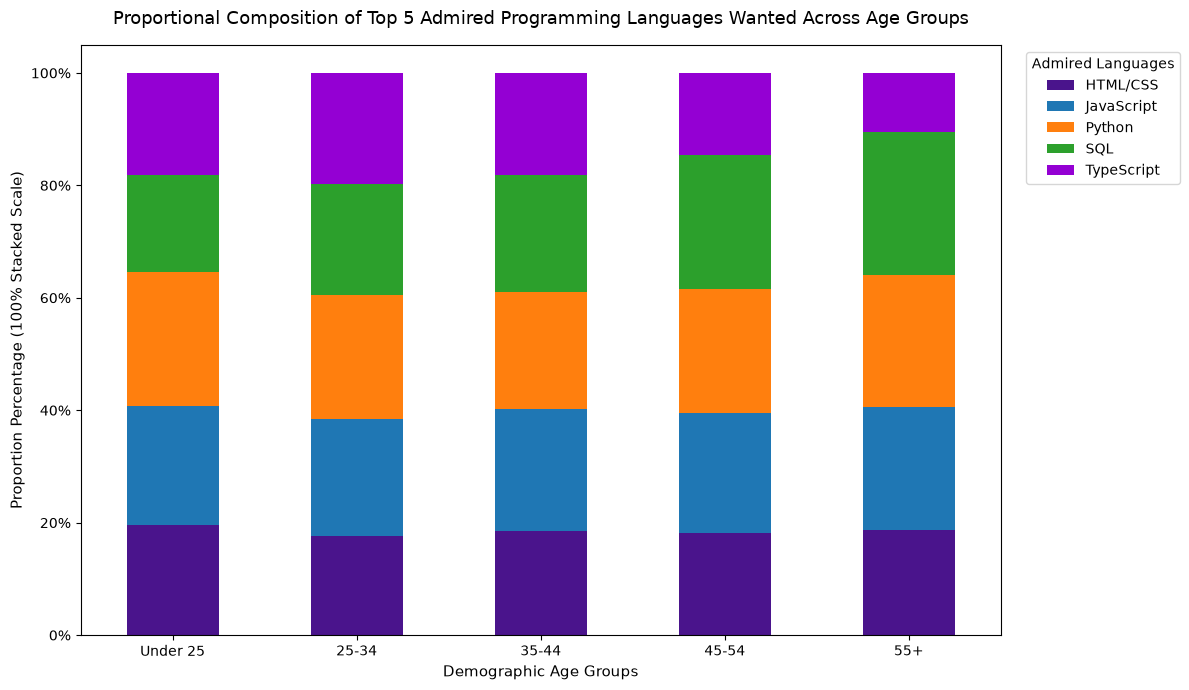

In [16]:
# 1. Clean Age strings and create categorical Age Groups
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
age_bins = [0, 24, 34, 44, 54, np.inf]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels)

# 2. Isolate relevant columns and drop empty entries 
df_lang = df.dropna(subset=['LanguageWantToWorkWith', 'AgeGroup']).copy()

# 3. Split semicolon strings into lists and explode rows (FIXED: Reset index drops duplicate tracking labels)
df_lang['LanguageWantToWorkWith'] = df_lang['LanguageWantToWorkWith'].str.split(';')
df_exploded = df_lang.explode('LanguageWantToWorkWith').reset_index(drop=True)

# 4. Identify the Top 5 overall most admired languages to prevent visual clutter
top_5_langs = df_exploded['LanguageWantToWorkWith'].value_counts().nlargest(5).index
df_filtered = df_exploded[df_exploded['LanguageWantToWorkWith'].isin(top_5_langs)].copy()

# 5. Cross-tabulate (pivot) to map Age Groups against Language frequencies
ct = pd.crosstab(df_filtered['AgeGroup'], df_filtered['LanguageWantToWorkWith'])

# 6. Normalize rows to sum up to 1 (100%) to calculate exact inner proportions
ct_proportions = ct.div(ct.sum(axis=1), axis=0)

# Create the stacked horizontal or vertical proportional chart
plt.figure(figsize=(12, 7))
ax = ct_proportions.plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 7), 
    color=['#4a148c', '#1f77b4', '#ff7f0e', '#2ca02c', '#9400d3']
)

# Visual layout adjustments and text formatting descriptions
plt.title('Proportional Composition of Top 5 Admired Programming Languages Wanted Across Age Groups', fontsize=13, pad=15)
plt.xlabel('Demographic Age Groups', fontsize=11)
plt.ylabel('Proportion Percentage (100% Stacked Scale)', fontsize=11)

# Format the Y-axis to show percentages cleanly instead of decimal floats
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Rotate labels completely horizontal for scannability
plt.xticks(rotation=0)

# Position the chart legend outside the boundaries so it doesn't overlap the segments
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Admired Languages')

plt.tight_layout()
plt.show()


##### 2. Stacked Chart for Technology Adoption by Employment Type


Explore how admired platforms (`PlatformAdmired`) differ across employment types (e.g., full-time, freelance)


/tmp/ipykernel_280/410218544.py:42: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

<Figure size 1300x700 with 0 Axes>

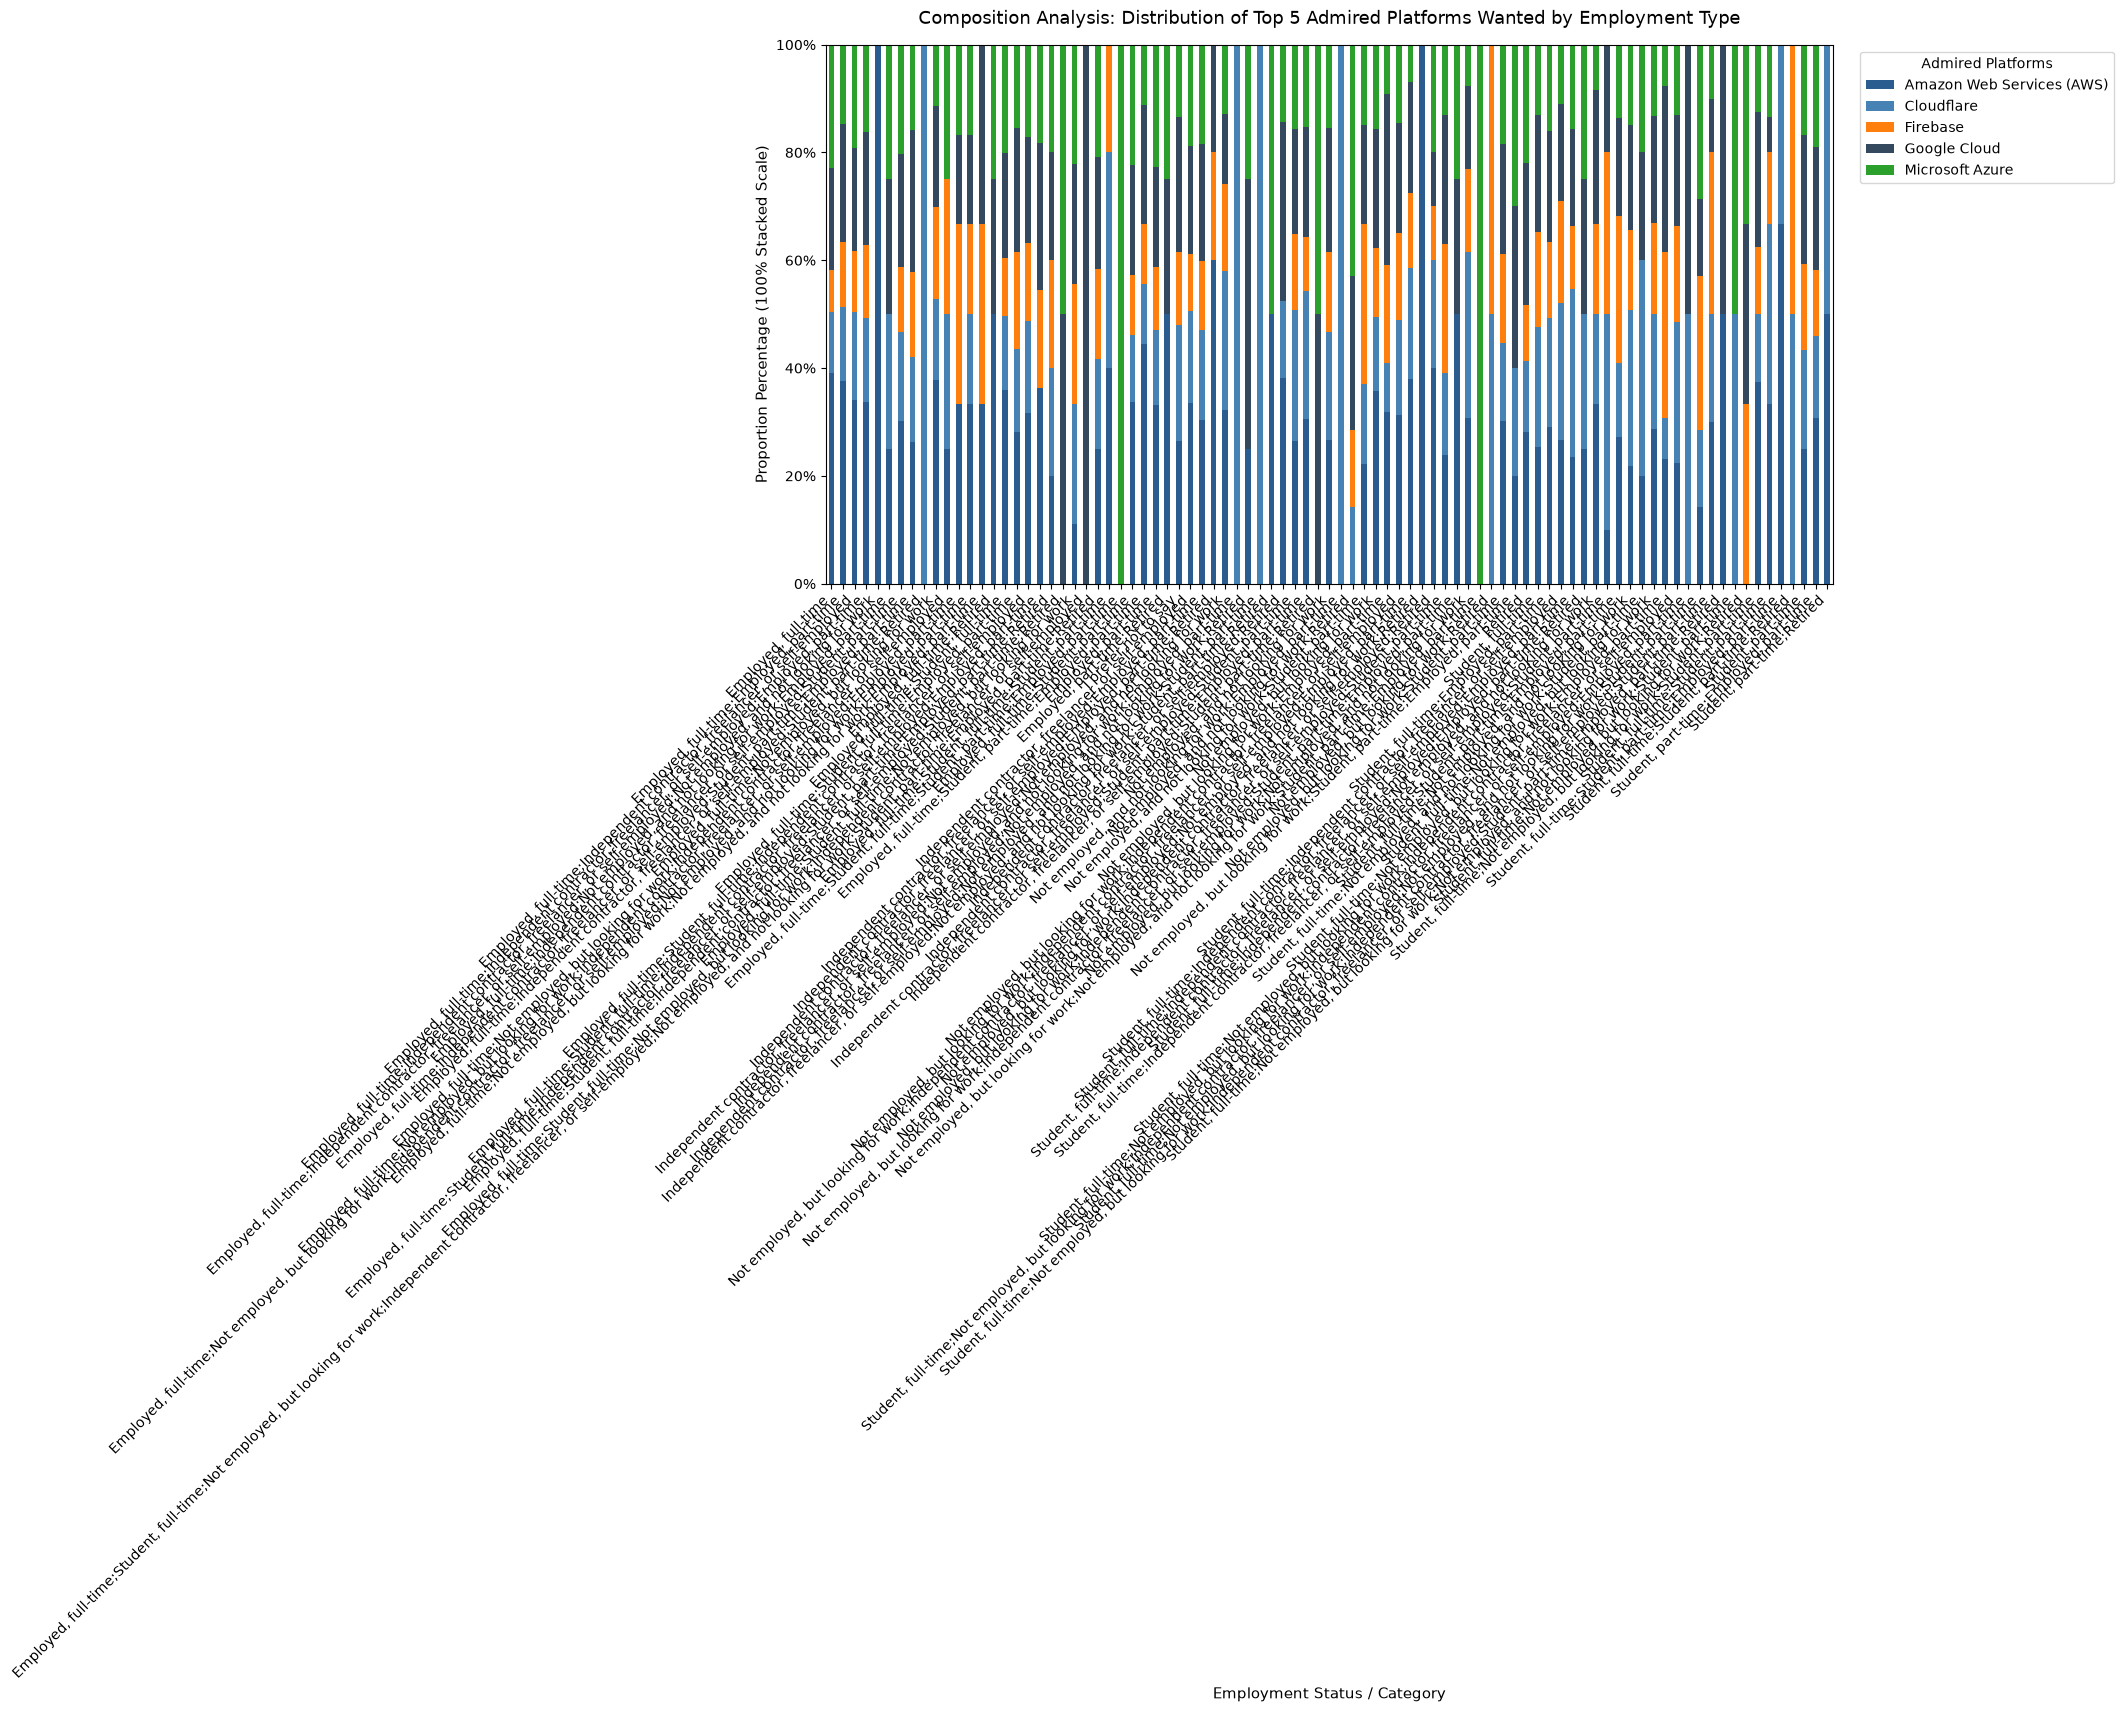

In [18]:
# 1. Isolate relevant columns and drop empty entries
df_plat = df.dropna(subset=['PlatformWantToWorkWith', 'Employment']).copy()

# 2. Split semicolon strings into lists and explode rows into distinct records
# FIXED: Adding .reset_index(drop=True) completely flattens duplicate row index tracking tags
df_plat['PlatformWantToWorkWith'] = df_plat['PlatformWantToWorkWith'].str.split(';')
df_exploded = df_plat.explode('PlatformWantToWorkWith').reset_index(drop=True)

# 3. Identify the Top 5 overall most admired platforms to keep the visualization clean
top_5_plats = df_exploded['PlatformWantToWorkWith'].value_counts().nlargest(5).index
df_filtered = df_exploded[df_exploded['PlatformWantToWorkWith'].isin(top_5_plats)].copy()

# 4. Cross-tabulate to map Employment Types (index) against Platform frequencies (columns)
ct = pd.crosstab(df_filtered['Employment'], df_filtered['PlatformWantToWorkWith'])

# 5. Normalize rows to sum up to 1 (100%) to calculate exact inner proportions
ct_proportions = ct.div(ct.sum(axis=1), axis=0)

# Create the stacked proportional chart
plt.figure(figsize=(13, 7))
ax = ct_proportions.plot(
    kind='bar', 
    stacked=True, 
    figsize=(13, 7), 
    color=['#2b5c8f', '#4682b4', '#ff7f0e', '#34495e', '#2ca02c'] # Professional tech layout palette
)

# Visual layout adjustments and text formatting descriptions
plt.title('Composition Analysis: Distribution of Top 5 Admired Platforms Wanted by Employment Type', fontsize=13, pad=15)
plt.xlabel('Employment Status / Category', fontsize=11)
plt.ylabel('Proportion Percentage (100% Stacked Scale)', fontsize=11)

# Format the Y-axis to show percentages cleanly instead of decimal floats
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Rotate labels slightly for clean layout design reading
plt.xticks(rotation=45, ha='right')

# Position the chart legend outside the boundaries so it doesn't overlap data segments
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Admired Platforms')

plt.tight_layout()
plt.show()


### Final Step: Review


In this lab, you focused on using stacked charts to understand the composition and comparison within the dataset. Stacked charts provided insights into job satisfaction, compensation, and preferred databases across age groups and employment types.


## Summary


After completing this lab, you will be able to:

- Use stacked charts to analyze the composition of data across categories, such as job satisfaction and compensation by age group.

- Compare data across different dimensions using stacked charts, enhancing your ability to communicate complex relationships in the data.

- Visualize distributions across multiple categories, such as employment type by satisfaction, to gain a deeper understanding of patterns within the dataset.


## Author:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
